# 02c · Grid-connectivity graph neural process emulator

Predict local **thickness and conductivity maps** from a process recipe and planned substrate XY.
Use a **two-layer, width-64 residual message-passing GNN** over each deposition grid. It trains on precisely the same eligible labeled locations as the point models.

**Prediction unit:** one feature row per location (recipe + physical X/Y + local temperature),
yielding thickness and conductivity at that location. Ridge/KRR/MLP/Random Forest predict independently,
whether queried alone or in a batch. Save point predictions with their identity/XY first; only then
pivot them into a grid for visualization, without averaging, interpolation, or smoothing. The GNN
also predicts per location, but is explicitly neighbor-aware and requires the full planned grid.

**Fixed comparison contract:** run notebook 01 once, then all five algorithm notebooks without
rerunning data preparation. Reuse the same material-stratified whole-deposition/identical-recipe
splits, features, train-only transforms, two log targets, and eligible labels. No spectra, measured
composition/properties, IDs, or label-availability flags enter the inputs. Whole-grid identity stays
intact. Models save separate outputs; no algorithm can overwrite another's run.

**Shared chemistry inputs:** source-formula descriptors (electronegativity, atomic mass/size,
ionization energy, elemental fractions, and independent reference band-gap statistics) replace
source-name one-hot columns. Recipe source/power slots remain paired. Reference gaps are not
measured film properties or certified target-phase values; missing coverage is explicit.
Power-weighted descriptors are not inferred deposited-film stoichiometry. See notebook 01 for
references, coverage, and training-only imputation. No architecture adds its own features.

**Frozen instructor-selected features:** notebook 01 uses the offline specification selected by
an instructor-only grouped training/validation comparison. Candidate additions include curated
composition descriptors, published MEGNet composition vectors, real frozen ALIGNN reference-crystal
vectors and compact reference DOS. Only selected blocks enter the matrices. Reference crystals/DOS
are not verified source phases or measured film information. No architecture downloads an encoder,
selects features, fits PCA, or changes preprocessing. All five models read the same checksummed
matrices. Your experiment changes the ML algorithm/architecture, not the data preparation.

**Expanded observations:** a position needs at least one observed property, not both. Ridge/KRR/forests
fit each output on its observed labels; neural models use a per-property masked MSE with equal
property weighting. Missing labels remain NaN, never fabricated. Each node also has a local
temperature from the source `absolute_temp_c` profile. Inference requires a planned/calibrated
temperature map; missing temperature is explicitly imputed, not assumed equal to initial temperature.
Original split assignments are frozen; new groups are material-balanced around them. The summary
also reports the original paired test points separately for an honest before/after comparison.

Workshop cycle: **baseline → hypothesis → one model change → validation → final reporting**.
The default 02 stays linear Ridge regardless of which model ranks first in notebook 03.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


### Load the shared process features and spatial splits

Code Summary: Loads notebook 01's shared features, target transforms, label masks, and grouped splits without rebuilding them. Each row represents process conditions at one substrate location; this model's results are saved in a separate experiment folder.


In [1]:
from pathlib import Path
import sys, json
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
HERE = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [parent, parent / '03_htem_conductivity']:
        if (candidate / 'htem_experiments.py').exists():
            HERE = candidate
            break
    if HERE is not None: break
if HERE is None:
    raise FileNotFoundError('Open from the workshop, HTEM module, or its examples folder.')
sys.path.insert(0, str(HERE))
import htem_workshop as htem
import htem_experiments as exp
ctx = exp.load_context(HERE)  # Validate and reuse notebook 01; NEVER redo preparation/splitting.
print('Shared frozen feature set:', ctx.manifest['frozen_feature_selection']['candidate'])
SEED = ctx.manifest['seed']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

EXPERIMENT_ID = 'grid_gnn'
RESULTS = HERE / 'outputs/htem_architectures' / EXPERIMENT_ID
RESULTS.mkdir(parents=True, exist_ok=True)
X_train, y_train = ctx.data['train']['X'], ctx.data['train']['y']
X_val, y_val = ctx.data['validation']['X'], ctx.data['validation']['y']
print('Same prepared data:', ctx.fingerprint['prepared_manifest_sha256'][:12])
display(pd.DataFrame([{'split': s, 'labeled_points': len(ctx.data[s]['X']),
                       'depositions': len(np.unique(ctx.data[s]['library_id'])),
                       'thickness_labels': int(ctx.data[s]['y_mask'][:, 0].sum()),
                       'conductivity_labels': int(ctx.data[s]['y_mask'][:, 1].sum())} for s in htem.SPLITS]))
print(f'{X_train.shape[1]} encoded inputs → 2 standardized log targets.')

Shared frozen feature set: curated_crystal_dos
Same prepared data: 4cc9f6386925


,split,labeled_points,depositions,thickness_labels,conductivity_labels
0,train,22272,520,21360,6377
1,validation,7127,166,6776,2260
2,test,7363,173,7182,2289


361 encoded inputs → 2 standardized log targets.


## 1. Fit the model; use validation, never test, for choices

**Hypothesis prompt:** “Local spatial patterns may benefit from neighboring recipe/position representations. Use independent full-grid graphs, geometry-only edges, a masked node loss, and validation-minimum checkpoints; never feed measured neighbor properties into messages. Keep the supplied data contract unchanged. Explain each change,
preserve reproducibility, and compare validation error before final test reporting.”

Each deposition is an independent four-neighbor grid graph. Node inputs are recipe + XY;
edges encode signed dx, signed dy, and distance (fixed 10 mm scale). Two residual message
layers aggregate learned neighbor messages, then predict two values **per location**, not a
pooled substrate average. Full planned grids include unlabeled nodes; only eligible labels
contribute to loss. The mask is not an input. No edges cross depositions in a batch.

This edge-aware mean-neighbor network is inspired by
[GraphSAGE](https://arxiv.org/abs/1706.02216), not a paper reproduction. Geometry provides an
inductive bias, not proof that sampling sites interact physically or a guarantee of improvement.

### Construct geometry-only graphs of substrate grids

Code Summary: Builds and visualizes a neighbor graph for each full substrate grid, including unlabeled positions. Connections depend only on geometry and never link different depositions.


,nodes,labeled_nodes,undirected_edges
split,,,
test,7612,7363,12629
train,22880,22272,37960
validation,7304,7127,12118


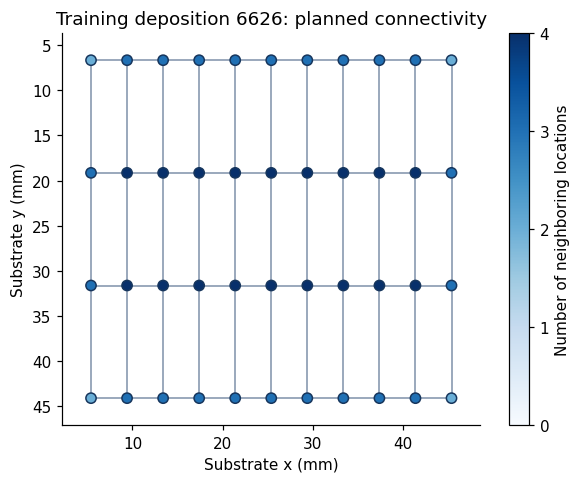

In [2]:
import htem_graph as gnn
graphs = exp.ensure_graphs(ctx)
display(ctx.graph_report.groupby('split')[['nodes', 'labeled_nodes', 'undirected_edges']].sum())
sample = graphs['train'][0]
fig = gnn.plot_grid_graph(sample.grid, f'Training deposition {sample.library_id}: planned connectivity')
fig.savefig(RESULTS / 'substrate_connectivity.png', bbox_inches='tight')
plt.show()

### Train a graph model with per-location predictions

Code Summary: Trains a graph neural network to predict properties at each substrate location rather than one value per deposition. Uses observed-label masks, cosine learning-rate decay, and patience-based stopping to restore the lowest-validation-loss model.


In [3]:
configuration = {'hidden_dim': 64, 'message_layers': 2, 'dropout': 0.05, 'lr': 5e-4,
                 'weight_decay': 1e-3, 'epochs': 300, 'patience': 40, 'batch_size': 16}
started = perf_counter()
model, history, training_note = gnn.fit_graph_model(graphs['train'], graphs['validation'], seed=SEED, **configuration)
fit_seconds = perf_counter() - started
trials = None

## 2. Inspect convergence and the restored checkpoint

AdamW, gradient clipping, cosine LR decay, and validation patience are configured above.
We restore **minimum validation MSE**; the epoch cap is a budget, not proof of convergence.
Change one architecture/optimization setting at a time. Plotting is separate from fitting.

### Inspect graph-model training and checkpoint selection

Code Summary: Plots training/validation loss and learning-rate histories, marks the restored validation-minimum model, and reports why training stopped. Reaching the epoch limit alone does not demonstrate convergence.


{'best_epoch': 68, 'epochs_run': 108, 'best_validation_MSE': 0.4632830321788788, 'stop_reason': 'validation patience', 'topology': 'bidirectional horizontal/vertical nearest grid-level neighbors; no diagonals or cross-library edges', 'edge_length_scale_mm': 10.0}


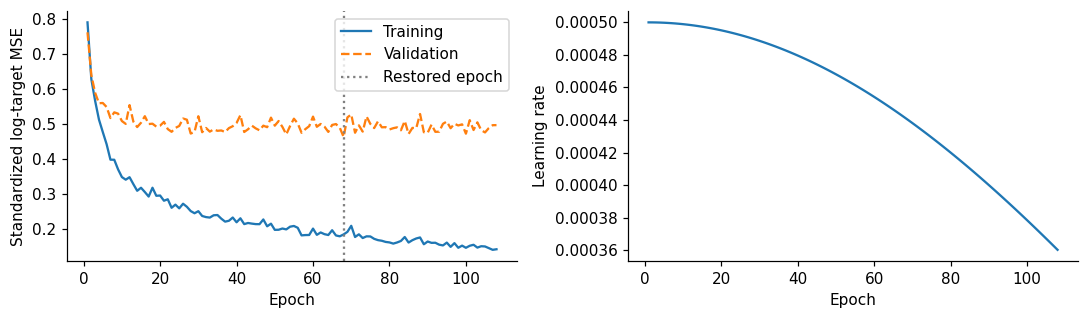

In [4]:
print(training_note)
fig = exp.plot_history(history, training_note)
fig.savefig(RESULTS / 'training_progress.png', bbox_inches='tight')
plt.show()

## Evaluate the same train, validation, and test points

**Analysis prompt:** “Report each property's error and the training/validation gap. Invert the
existing transforms, preserve library/position/XY, and show parity plots for all three splits.
Do not tune using test results. Be honest about weak conductivity predictions.”

Conductivity log error is in decades: 1 decade means a factor of 10. Raw conductivity metrics are
also saved, but extreme values dominate them. These observational models are not causal simulators.

### Evaluate per-location predictions and save the model

Code Summary: Predicts each location, converts results back to physical units, and shows train/validation/test parity plots. Saves the model, aligned predictions, metrics, and reproducibility records; evaluation uses only observed labels for each property.


Validation score (mean standardized RMSE): 0.6737
Standardized target MSE: {'train': 0.184, 'validation': 0.4633, 'test': 0.6865}


,split,target,MAE,MSE,RMSE,R2,n
0,train,thickness_um,0.0972,0.0381,0.1951,0.8263,21360
2,train,log10_conductivity,0.6019,0.7565,0.8698,0.8126,6377
3,validation,thickness_um,0.1378,0.0527,0.2296,0.6844,6776
5,validation,log10_conductivity,1.1850,2.3964,1.5480,0.4399,2260
6,test,thickness_um,0.1701,0.0864,0.2939,0.5633,7182
8,test,log10_conductivity,1.3611,3.3626,1.8337,0.3128,2289


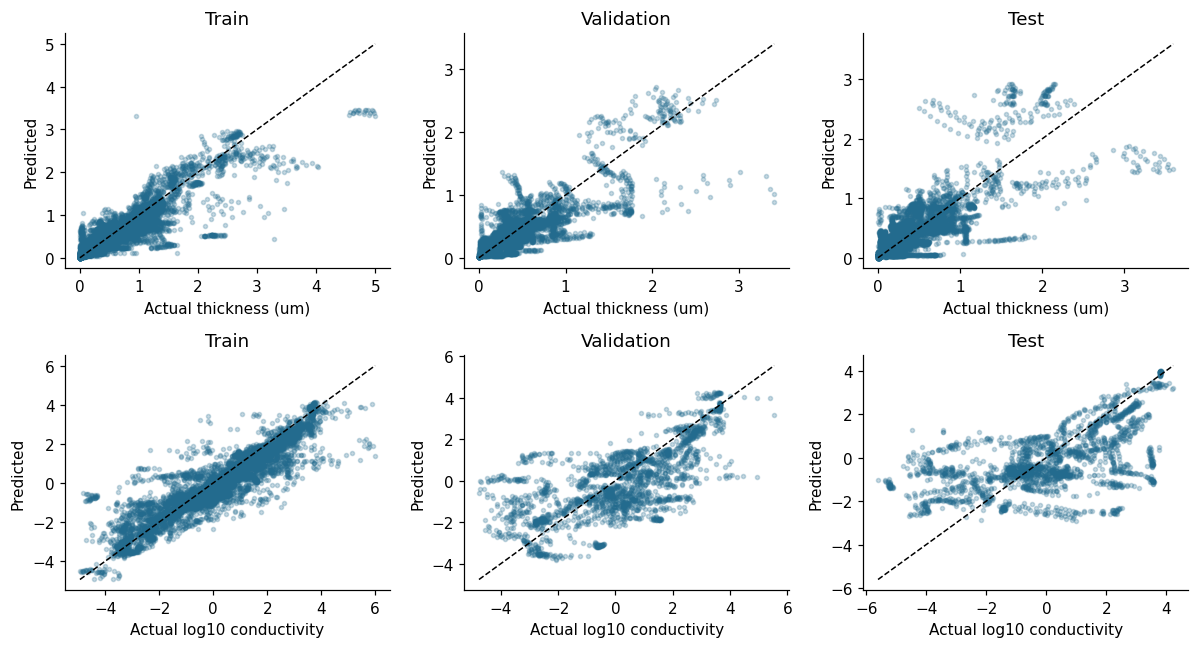

In [5]:
RESULTS, metrics, run = exp.evaluate_and_save(
    ctx, model, EXPERIMENT_ID, configuration, fit_seconds,
    history=history, training_note=training_note, trials=trials)
print(f"Validation score (mean standardized RMSE): {run['validation_score']:.4f}")
print('Standardized target MSE:', {s: round(v, 4) for s, v in run['standardized_MSE'].items()})
display(metrics[metrics.target.ne('conductivity_S_cm')].round(4))
predictions = pd.read_csv(RESULTS / 'predictions.csv', dtype={'sample_id': str})
fig = exp.plot_parity(predictions)
fig.savefig(RESULTS / 'parity_all_splits.png', bbox_inches='tight')
plt.show()

## Compare maps for the same held-out deposition

All algorithm notebooks select the same test library by eligible point count, not favorable error.
Predict its **full planned grid**; missing measured labels remain blank. No interpolation, fixed-size
reshape, or averaging across positions/depositions is allowed. Color limits match actual/predicted.

### Reconstruct measured and predicted substrate maps

Code Summary: Reconstructs measured and predicted maps for one held-out deposition using each location's exact x/y coordinates. Side-by-side maps reveal property levels and spatial gradients without averaging different depositions or filling missing locations.


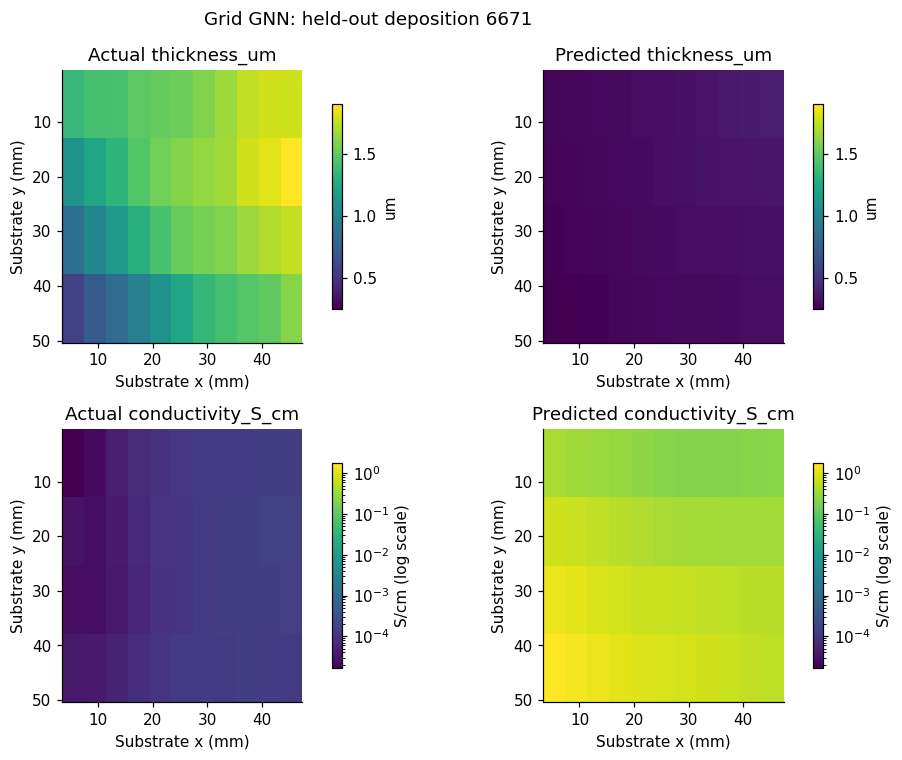

In [6]:
full_map = pd.read_csv(RESULTS / 'heldout_map.csv')
MAP_LIBRARY_ID = int(run['map_library_id'])
fig = htem.plot_substrate_maps(full_map, MAP_LIBRARY_ID)
fig.suptitle(f"{run['name']}: held-out deposition {MAP_LIBRARY_ID}")
fig.tight_layout()
fig.savefig(RESULTS / 'heldout_maps.png', bbox_inches='tight')
plt.show()

## Predict a recipe on a requested grid using the saved model

Edit `recipe` below, or supply planned `position/x_mm/y_mm` coordinates in the HTEM substrate frame.
Do not pass measured outputs or stage/focus `xyz_mm`. Use a **full planned grid** for graph inference;
changing nodes changes neighborhoods. For grids missing entire coordinate levels, specify known
`spacing_mm=(dx, dy)` rather than guessing nominal spacing. Load only trusted local joblib artifacts.

### Reload the model and predict an editable process grid

Code Summary: Reloads the model and checks that it reproduces saved predictions, then predicts thickness/conductivity maps for editable process settings and substrate locations. No measured film properties are required as inputs; the GNN uses a full planned grid rather than independent rows.


C:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\03_htem_conductivity\htem_experiments.py:239: UserWarning: Optional recipe settings missing: using training-only imputation.
  warnings.warn("Optional recipe settings missing: using training-only imputation.")


C:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\03_htem_conductivity\htem_experiments.py:239: UserWarning: Optional recipe settings missing: using training-only imputation.
  warnings.warn("Optional recipe settings missing: using training-only imputation.")


,RECIPE SETTINGS
pdac,1
deposition_sample_time_min,240.0
deposition_initial_temp_c,400.0
deposition_base_pressure_mtorr,0.0012
deposition_growth_pressure_mtorr,20.0
deposition_compounds,"[Cu2O, ZnO, ZnO]"
deposition_power,"[50.0, 20.0, 10.0]"
deposition_gases,"[ARGON, None, None]"
deposition_gas_flow_sccm,"[20.0, nan, nan]"
deposition_substrate_material,Eagle 2k


,position,x_mm,y_mm,local_temperature_C,predicted_thickness_um,predicted_conductivity_S_cm
0,1,5.4,6.65,405.4,0.275129,0.390103
1,2,9.4,6.65,405.4,0.279403,0.342353
2,3,13.4,6.65,405.4,0.286429,0.305010
3,4,17.4,6.65,405.4,0.294569,0.271083
4,5,21.4,6.65,405.4,0.304873,0.241049


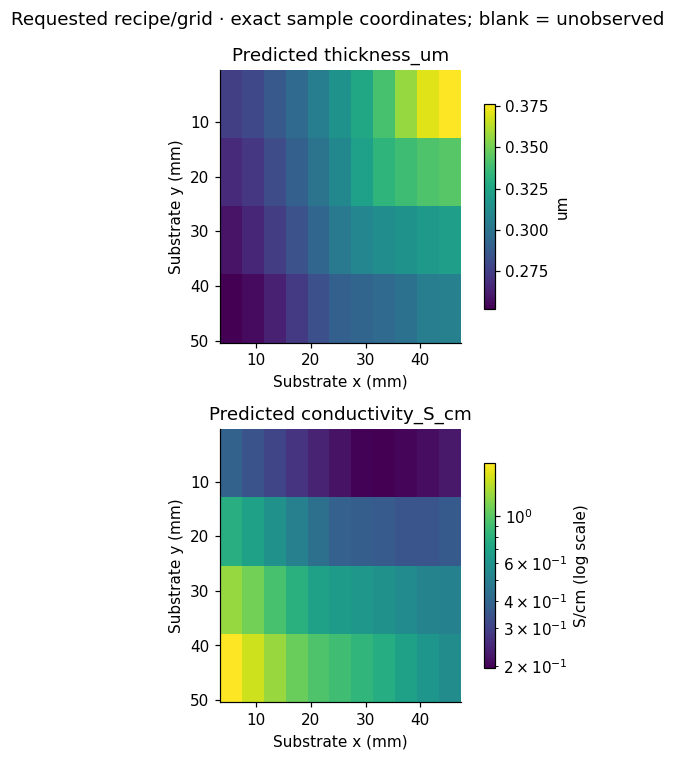

In [7]:
fitted = joblib.load(RESULTS / 'model.joblib')
def predict_substrate(recipe, grid, spacing_mm=None):
    return exp.predict_substrate(fitted, recipe, grid, spacing_mm)

reference_grid = full_map[['position', 'x_mm', 'y_mm', 'local_temperature_C']].copy()
reference_recipe = exp.example_recipe(ctx, MAP_LIBRARY_ID)
reference_map = predict_substrate(reference_recipe, reference_grid)
# Validate the unchanged reference BEFORE trying a modified recipe or grid.
np.testing.assert_allclose(reference_map[['predicted_thickness_um', 'predicted_conductivity_S_cm']],
                           full_map[['predicted_thickness_um', 'predicted_conductivity_S_cm']], rtol=5e-5, atol=1e-7)
recipe = dict(reference_recipe)
grid = reference_grid.copy()  # EDIT planned grid here, after the reference check.
# EDIT a planned temperature profile, for example: grid['local_temperature_C'] = 350
# Changing initial temperature alone does NOT redefine the specified local profile.
predicted_map = predict_substrate(recipe, grid)
display(pd.Series(recipe, name='RECIPE SETTINGS').to_frame())
display(predicted_map.head())
fig = htem.plot_substrate_maps(predicted_map)
fig.savefig(RESULTS / 'requested_recipe_maps.png', bbox_inches='tight')
plt.show()
predicted_map.to_csv(RESULTS / 'requested_recipe_map.csv', index=False)

Record your hypothesis, configuration, validation outcome, and next experiment. Run all five
architecture notebooks before `03_HTEM_Compare_Architectures.ipynb`. The comparison rejects stale
preparation, different labeled rows/targets, missing runs, and changed result files. Better scores
on one fixed holdout do not establish statistical superiority; do not repeatedly optimize on test.